# EN3160 - Image Processing and Machine Vision
## Assignment 03: Neural Networks

**Name:** Akhila Nisal Wedamestrige  
**Index Number:** 230687P  
**Department:** Electronic and Telecommunication Engineering  
**University:** University of Moratuwa  

### GitHub Repository

[EN3160 Assignment 03](https://github.com/AkhilaNisal/EN3160_Assignment_3)

## Question 1

In [29]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# GPU configuration for Colab
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5),
                          (0.5, 0.5, 0.5))]
)

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse',
           'ship', 'truck')

Using device: cuda


## Define Network Parameters

In [30]:
# 2. Define Network Parameters

Din = 3 * 32 * 32    # Input size
H = 100              # Hidden layer neurons
K = 10               # Output classes

std = 0.01

# Initialize weights and biases
w1 = torch.randn(Din, H, device=device) * std
b1 = torch.zeros(H, device=device)

w2 = torch.randn(H, K, device=device) * std
b2 = torch.zeros(K, device=device)

# Hyperparameters
iterations = 10      # 10 epochs
lr = 0.1             # Learning rate
lr_decay = 0.9
reg = 0              # Regularization

loss_history = []

## Training Loop

In [31]:
# 3. Training Loop

for t in range(iterations):

    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):

        # Get inputs and labels
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device)
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(
            labels, K
        ).float()

        # Forward pass
        # Hidden layer
        z1 = x_train.mm(w1) + b1
        a1 = torch.sigmoid(z1)

        # Output layer
        z2 = a1.mm(w2) + b2

        # Softmax probabilities
        y_pred = torch.softmax(z2, dim=1)

        # Cross-Entropy Loss
        loss = -torch.sum(
            y_train_onehot * torch.log_softmax(z2, dim=1)
        ) / Ntr

        loss = loss + reg * (
            torch.sum(w1 ** 2) +
            torch.sum(w2 ** 2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Manual Backpropagation
        # Output layer
        dz2 = (y_pred - y_train_onehot) / Ntr

        dw2 = a1.t().mm(dz2) + 2 * reg * w2
        db2 = dz2.sum(dim=0)

        # Hidden layer
        da1 = dz2.mm(w2.t())

        dz1 = da1 * a1 * (1 - a1)

        dw1 = x_train.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter Update
        w1 -= lr * dw1
        b1 -= lr * db1

        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    print(
        f"Epoch {t+1}/{iterations}, "
        f"Loss: {running_loss / len(trainloader):.4f}"
    )

    # Learning rate decay
    lr *= lr_decay

Epoch 1/10, Loss: 1.9004
Epoch 2/10, Loss: 1.7147
Epoch 3/10, Loss: 1.6484
Epoch 4/10, Loss: 1.5996
Epoch 5/10, Loss: 1.5596
Epoch 6/10, Loss: 1.5251
Epoch 7/10, Loss: 1.4952
Epoch 8/10, Loss: 1.4692
Epoch 9/10, Loss: 1.4451
Epoch 10/10, Loss: 1.4241


## Plotting the Loss History

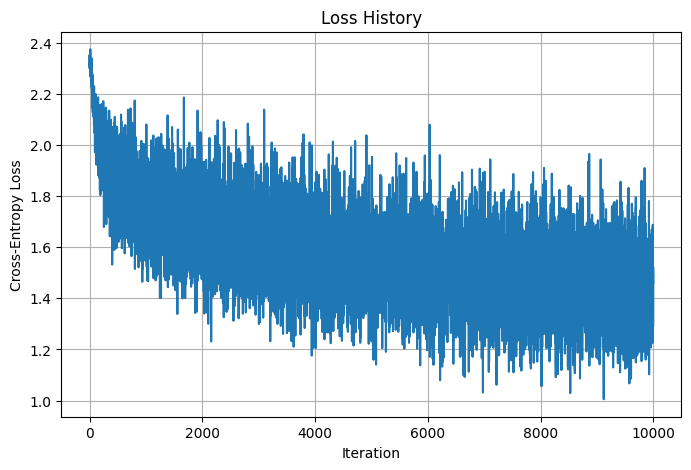

In [32]:
# 4. Plotting the Loss History

plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Cross-Entropy Loss")

plt.grid(True)
plt.show()

## Calculate Accuracy on Training Set

In [33]:
# 5. Calculate Accuracy on Training Set

correct_train = 0
total_train = 0

with torch.no_grad():

    for data in trainloader:

        inputs, labels = data

        inputs = inputs.to(device)
        labels = labels.to(device)

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        z1 = x_train.mm(w1) + b1
        a1 = torch.sigmoid(z1)

        y_train_pred = a1.mm(w2) + b2

        predicted_train = torch.argmax(
            y_train_pred, dim=1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted_train == labels
        ).sum().item()

train_acc = 100 * correct_train / total_train

print(f"Training accuracy: {train_acc:.2f}%")

Training accuracy: 52.09%


## Calculate Accuracy on Test Set

In [34]:
# 6. Calculate Accuracy on Test Set

correct_test = 0
total_test = 0

with torch.no_grad():

    for data in testloader:

        inputs, labels = data

        inputs = inputs.to(device)
        labels = labels.to(device)

        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        z1 = x_test.mm(w1) + b1
        a1 = torch.sigmoid(z1)

        y_test_pred = a1.mm(w2) + b2

        predicted_test = torch.argmax(
            y_test_pred, dim=1
        )

        total_test += labels.size(0)

        correct_test += (
            predicted_test == labels
        ).sum().item()

test_acc = 100 * correct_test / total_test

print(f"Test accuracy: {test_acc:.2f}%")

Test accuracy: 47.21%


## Question 1 - Results and Discussion

A fully connected neural network with a **100-neuron sigmoid hidden layer** was implemented for CIFAR-10 classification. Cross-entropy loss and manual backpropagation were used to train the network for 10 epochs.

The training loss decreased from **1.9004 to 1.4241**, indicating successful learning. The final training accuracy was **52.09%**, while the test accuracy was **47.21%**, resulting in a generalization gap of 4.88 percentage points.

Although the network learned useful features, its classification accuracy remained limited. This is mainly because flattening the images removes explicit spatial structure, making it difficult to efficiently learn local image features.

**Conclusion:** The modified network successfully learned a nonlinear classification function, but its performance highlights the limitations of fully connected networks for image classification.

# Question 2: Convolutional Neural Networks

In [35]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


### Define preprocessing

In [36]:
transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

### Load MNIST

In [37]:
batch_size = 64

trainset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

testset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

trainloader = DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testloader = DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("Training samples:", len(trainset))
print("Test samples:", len(testset))
print("Image shape:", trainset[0][0].shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 502kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.95MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.5MB/s]

Training samples: 60000
Test samples: 10000
Image shape: torch.Size([1, 32, 32])


### Visualize MNIST images

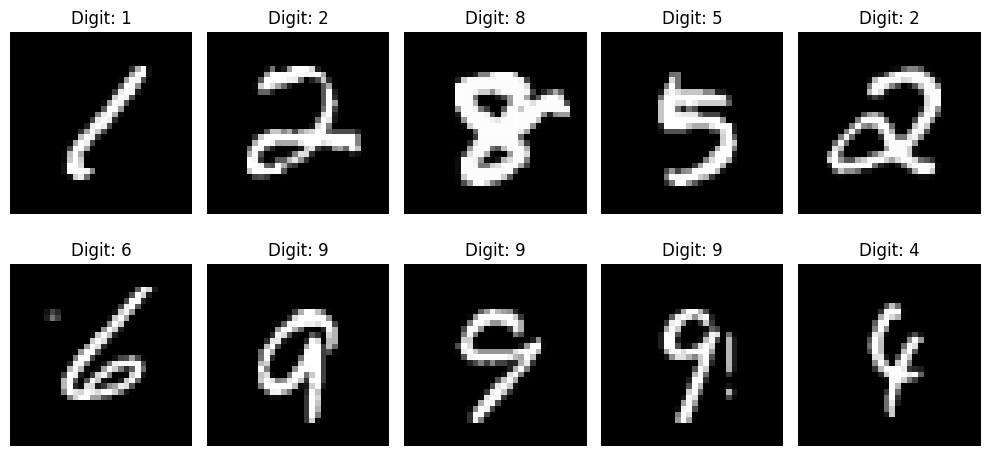

In [38]:
images, labels = next(iter(trainloader))

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):

    img = images[i].squeeze().numpy()
    img = img * 0.5 + 0.5

    ax.imshow(img, cmap="gray")
    ax.set_title(f"Digit: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Define the network

In [39]:
class LeNet5(nn.Module):

    def __init__(self):
        super(LeNet5, self).__init__()

        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=6,
            kernel_size=5
        )

        self.pool = nn.AvgPool2d(
            kernel_size=2,
            stride=2
        )

        self.conv2 = nn.Conv2d(
            in_channels=6,
            out_channels=16,
            kernel_size=5
        )

        self.conv3 = nn.Conv2d(
            in_channels=16,
            out_channels=120,
            kernel_size=5
        )

        self.fc1 = nn.Linear(120, 84)
        self.fc2 = nn.Linear(84, 10)

    def forward(self, x):

        # Conv1: 1x32x32 -> 6x28x28
        x = torch.tanh(self.conv1(x))

        # Pool1: 6x28x28 -> 6x14x14
        x = self.pool(x)

        # Conv2: 6x14x14 -> 16x10x10
        x = torch.tanh(self.conv2(x))

        # Pool2: 16x10x10 -> 16x5x5
        x = self.pool(x)

        # Conv3: 16x5x5 -> 120x1x1
        x = torch.tanh(self.conv3(x))

        # Flatten: 120x1x1 -> 120
        x = torch.flatten(x, 1)

        # Fully connected layers
        x = torch.tanh(self.fc1(x))

        # Output logits
        x = self.fc2(x)

        return x


model_lenet = LeNet5().to(device)

print(model_lenet)

LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (conv3): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=120, out_features=84, bias=True)
  (fc2): Linear(in_features=84, out_features=10, bias=True)
)


### Check the output shape

In [40]:
sample_images, sample_labels = next(iter(trainloader))

sample_images = sample_images.to(device)

with torch.no_grad():
    output = model_lenet(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([64, 1, 32, 32])
Output shape: torch.Size([64, 10])


### Define the loss and optimizer

In [41]:
criterion = nn.CrossEntropyLoss()

optimizer_lenet = optim.Adam(
    model_lenet.parameters(),
    lr=0.001
)

epochs = 10

### Define training and evaluation functions

In [42]:
def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predicted = outputs.argmax(dim=1)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc


@torch.no_grad()
def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        running_loss += loss.item() * labels.size(0)

        predicted = outputs.argmax(dim=1)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

### Train LeNet-5 for 10 epochs

In [43]:
history_lenet = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        model_lenet,
        trainloader,
        optimizer_lenet,
        criterion
    )

    test_loss, test_acc = evaluate(
        model_lenet,
        testloader,
        criterion
    )

    history_lenet["train_loss"].append(train_loss)
    history_lenet["train_acc"].append(train_acc)

    history_lenet["test_loss"].append(test_loss)
    history_lenet["test_acc"].append(test_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}%"
    )

Epoch [1/10] | Train Loss: 0.2750 | Train Acc: 91.99% | Test Loss: 0.1112 | Test Acc: 96.59%
Epoch [2/10] | Train Loss: 0.0914 | Train Acc: 97.17% | Test Loss: 0.0645 | Test Acc: 97.95%
Epoch [3/10] | Train Loss: 0.0609 | Train Acc: 98.12% | Test Loss: 0.0550 | Test Acc: 98.19%
Epoch [4/10] | Train Loss: 0.0475 | Train Acc: 98.53% | Test Loss: 0.0543 | Test Acc: 98.31%
Epoch [5/10] | Train Loss: 0.0391 | Train Acc: 98.80% | Test Loss: 0.0517 | Test Acc: 98.24%
Epoch [6/10] | Train Loss: 0.0321 | Train Acc: 99.03% | Test Loss: 0.0469 | Test Acc: 98.46%
Epoch [7/10] | Train Loss: 0.0264 | Train Acc: 99.15% | Test Loss: 0.0462 | Test Acc: 98.61%
Epoch [8/10] | Train Loss: 0.0235 | Train Acc: 99.23% | Test Loss: 0.0489 | Test Acc: 98.36%
Epoch [9/10] | Train Loss: 0.0185 | Train Acc: 99.43% | Test Loss: 0.0529 | Test Acc: 98.43%
Epoch [10/10] | Train Loss: 0.0191 | Train Acc: 99.38% | Test Loss: 0.0510 | Test Acc: 98.46%


### Plot LeNet-5 training curves

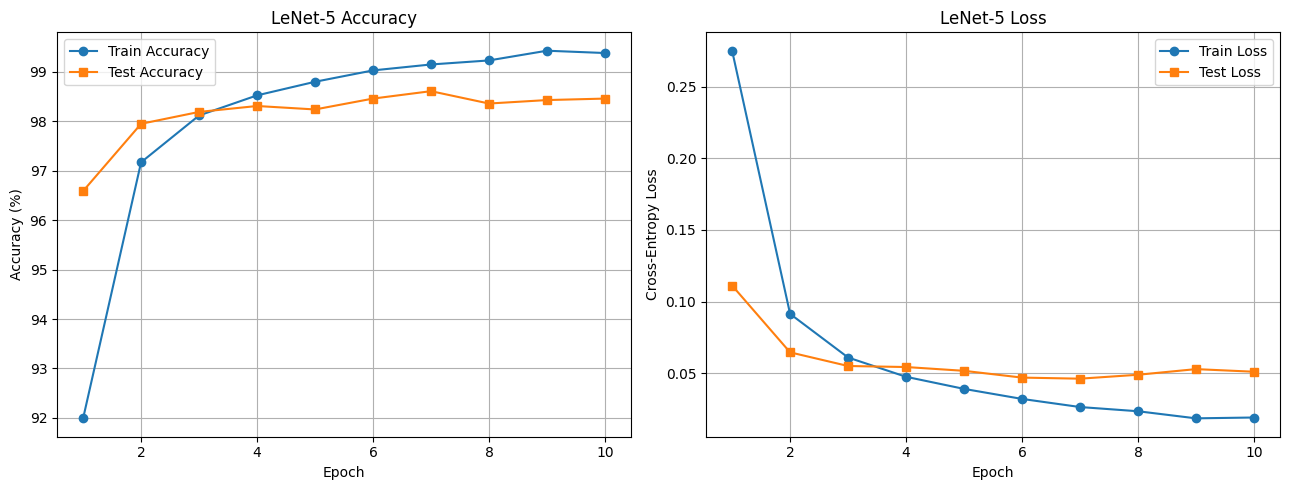

In [44]:
epoch_numbers = range(1, epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    epoch_numbers,
    history_lenet["train_acc"],
    "o-",
    label="Train Accuracy"
)

axes[0].plot(
    epoch_numbers,
    history_lenet["test_acc"],
    "s-",
    label="Test Accuracy"
)

axes[0].set_title("LeNet-5 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epoch_numbers,
    history_lenet["train_loss"],
    "o-",
    label="Train Loss"
)

axes[1].plot(
    epoch_numbers,
    history_lenet["test_loss"],
    "s-",
    label="Test Loss"
)

axes[1].set_title("LeNet-5 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("Q2_LeNet5_Curves.png", dpi=200)
plt.show()

### Generate the confusion matrix

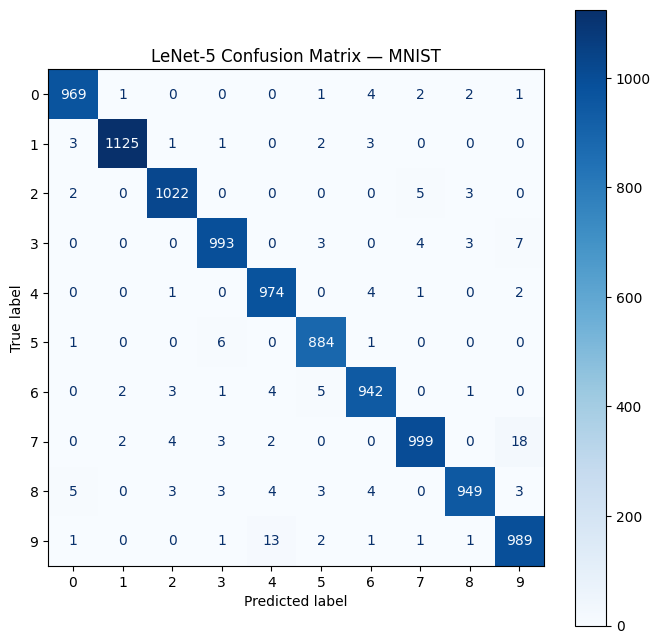

In [45]:
y_true = []
y_pred = []

model_lenet.eval()

with torch.no_grad():

    for images, labels in testloader:

        images = images.to(device)

        outputs = model_lenet(images)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10))
)

fig, ax = plt.subplots(figsize=(8, 8))

disp.plot(ax=ax, cmap="Blues", values_format="d")

plt.title("LeNet-5 Confusion Matrix — MNIST")
plt.savefig("Q2_LeNet5_Confusion_Matrix.png", dpi=200)
plt.show()

## Q2(b) - Implement a modern small CNN

### Define the modern CNN

In [46]:
class ModernCNN(nn.Module):

    def __init__(self):
        super(ModernCNN, self).__init__()

        # Convolutional layer 1
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        # Convolutional layer 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        # Convolutional layer 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        # Pooling
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Dropout
        self.dropout = nn.Dropout(p=0.5)

        # Fully connected layers
        self.fc1 = nn.Linear(128 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(torch.relu(self.bn1(self.conv1(x))))

        x = self.pool(torch.relu(self.bn2(self.conv2(x))))

        x = self.pool(torch.relu(self.bn3(self.conv3(x))))

        x = torch.flatten(x, 1)

        x = torch.relu(self.fc1(x))

        x = self.dropout(x)

        x = self.fc2(x)

        return x


torch.manual_seed(42)
model_modern = ModernCNN().to(device)

print(model_modern)

ModernCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


### Set up training

In [47]:
optimizer_modern = optim.Adam(
    model_modern.parameters(),
    lr=0.001
)

# Reuse the existing criterion
# criterion = nn.CrossEntropyLoss()

epochs = 10

print("Modern CNN parameters:",
      sum(p.numel() for p in model_modern.parameters()))

Modern CNN parameters: 356682


### Train the modern CNN

In [48]:
history_modern = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        model_modern,
        trainloader,
        optimizer_modern,
        criterion
    )

    test_loss, test_acc = evaluate(
        model_modern,
        testloader,
        criterion
    )

    history_modern["train_loss"].append(train_loss)
    history_modern["train_acc"].append(train_acc)

    history_modern["test_loss"].append(test_loss)
    history_modern["test_acc"].append(test_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc:.2f}%"
    )

Epoch [1/10] | Train Loss: 0.2089 | Train Acc: 93.81% | Test Loss: 0.0452 | Test Acc: 98.55%
Epoch [2/10] | Train Loss: 0.0891 | Train Acc: 97.31% | Test Loss: 0.0383 | Test Acc: 98.69%
Epoch [3/10] | Train Loss: 0.0675 | Train Acc: 98.05% | Test Loss: 0.0371 | Test Acc: 98.94%
Epoch [4/10] | Train Loss: 0.0575 | Train Acc: 98.32% | Test Loss: 0.0302 | Test Acc: 98.98%
Epoch [5/10] | Train Loss: 0.0503 | Train Acc: 98.50% | Test Loss: 0.0265 | Test Acc: 99.18%
Epoch [6/10] | Train Loss: 0.0434 | Train Acc: 98.72% | Test Loss: 0.0202 | Test Acc: 99.33%
Epoch [7/10] | Train Loss: 0.0386 | Train Acc: 98.81% | Test Loss: 0.0226 | Test Acc: 99.37%
Epoch [8/10] | Train Loss: 0.0331 | Train Acc: 98.97% | Test Loss: 0.0262 | Test Acc: 99.25%
Epoch [9/10] | Train Loss: 0.0286 | Train Acc: 99.10% | Test Loss: 0.0235 | Test Acc: 99.37%
Epoch [10/10] | Train Loss: 0.0275 | Train Acc: 99.11% | Test Loss: 0.0186 | Test Acc: 99.48%


## Q2(c) - Compare both networks

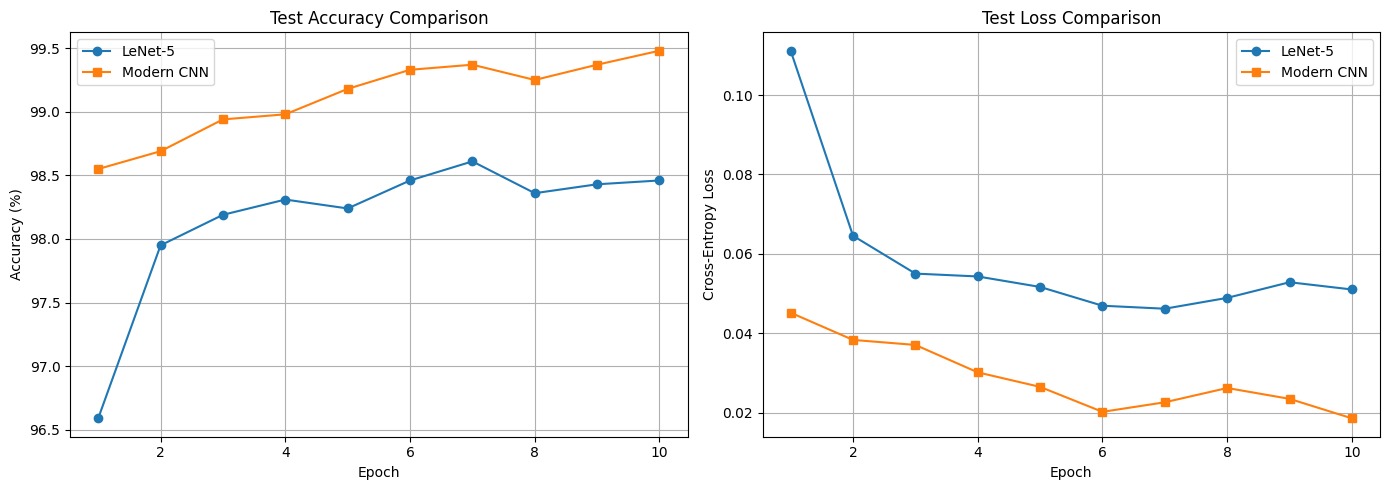

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ep = range(1, 11)

# Test accuracy
axes[0].plot(ep, history_lenet["test_acc"],
             "o-", label="LeNet-5")
axes[0].plot(ep, history_modern["test_acc"],
             "s-", label="Modern CNN")

axes[0].set_title("Test Accuracy Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(True)

# Test loss
axes[1].plot(ep, history_lenet["test_loss"],
             "o-", label="LeNet-5")
axes[1].plot(ep, history_modern["test_loss"],
             "s-", label="Modern CNN")

axes[1].set_title("Test Loss Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("Q2_Model_Comparison.png", dpi=200)
plt.show()

### Confusion matrix for modern CNN

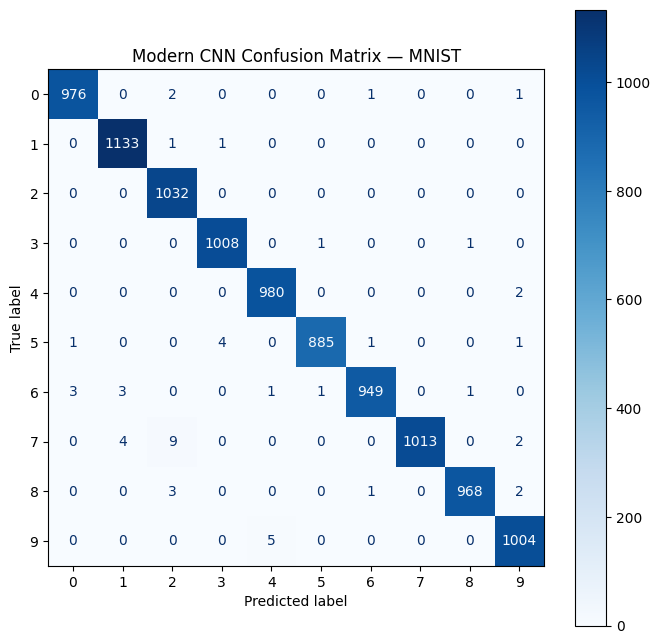

In [50]:
y_true_modern = []
y_pred_modern = []

model_modern.eval()

with torch.no_grad():

    for images, labels in testloader:

        images = images.to(device)

        outputs = model_modern(images)

        predicted = outputs.argmax(dim=1)

        y_true_modern.extend(labels.numpy())
        y_pred_modern.extend(predicted.cpu().numpy())

cm_modern = confusion_matrix(y_true_modern, y_pred_modern)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_modern,
    display_labels=list(range(10))
)

fig, ax = plt.subplots(figsize=(8, 8))

disp.plot(ax=ax, cmap="Blues", values_format="d")

plt.title("Modern CNN Confusion Matrix — MNIST")
plt.savefig("Q2_Modern_CNN_Confusion_Matrix.png", dpi=200)
plt.show()

### Final accuracy comparison

In [52]:
print("=" * 55)
print("Q2: LeNet-5 vs Modern CNN")
print("=" * 55)

print(f"{'Model':<18} {'Train Acc':>12} {'Test Acc':>12}")
print("-" * 55)

print(
    f"{'LeNet-5':<18}"
    f"{history_lenet['train_acc'][-1]:>11.2f}%"
    f"{history_lenet['test_acc'][-1]:>11.2f}%"
)

print(
    f"{'Modern CNN':<18}"
    f"{history_modern['train_acc'][-1]:>11.2f}%"
    f"{history_modern['test_acc'][-1]:>11.2f}%"
)

Q2: LeNet-5 vs Modern CNN
Model                 Train Acc     Test Acc
-------------------------------------------------------
LeNet-5                 99.38%      98.46%
Modern CNN              99.11%      99.48%


## Question 2 - and Discussion

LeNet-5 and a modern three-layer CNN were trained on MNIST for 10 epochs under the same training conditions.

| Model | Training Accuracy | Test Accuracy |
|---|---:|---:|
| LeNet-5 | 99.38% | 98.46% |
| Modern CNN | 99.11% | 99.48% |

Both models achieved high classification accuracy. However, the modern CNN obtained **1.02 percentage points higher test accuracy**, making only 52 incorrect predictions compared with 154 for LeNet-5.

The training curves showed that both models learned effectively. The modern CNN achieved better final test performance, potentially benefiting from batch normalization, ReLU activation, max pooling, and dropout.

The modern CNN's reported test accuracy was slightly higher than its training accuracy. This can occur because dropout is active during training but disabled during evaluation, and training accuracy is recorded while model parameters are being updated.

**Conclusion:** The modern CNN demonstrated better generalization than LeNet-5 under the experimental conditions, highlighting the effectiveness of the selected modern architectural techniques.

# Question 3: Transfer Learning with ResNet-18

In [53]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler

import torchvision
from torchvision import datasets, models, transforms
from torchvision.models import ResNet18_Weights

import numpy as np
import matplotlib.pyplot as plt
import time
import os
import copy

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [54]:
!wget -q https://download.pytorch.org/tutorial/hymenoptera_data.zip

!unzip -q -o hymenoptera_data.zip -d data/

data_dir = "data/hymenoptera_data"

print("Dataset downloaded successfully!")
print("Folders:", os.listdir(data_dir))

Dataset downloaded successfully!
Folders: ['val', 'train']


### Define transformations

In [55]:
data_transforms = {

    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}

### Create DataLoaders

In [56]:
image_datasets = {
    x: datasets.ImageFolder(
        os.path.join(data_dir, x),
        data_transforms[x]
    )
    for x in ["train", "val"]
}

dataloaders = {
    x: torch.utils.data.DataLoader(
        image_datasets[x],
        batch_size=4,
        shuffle=(x == "train"),
        num_workers=2
    )
    for x in ["train", "val"]
}

dataset_sizes = {
    x: len(image_datasets[x])
    for x in ["train", "val"]
}

class_names = image_datasets["train"].classes

print("Classes:", class_names)
print("Training images:", dataset_sizes["train"])
print("Validation images:", dataset_sizes["val"])

Classes: ['ants', 'bees']
Training images: 244
Validation images: 153


### Visualize sample images

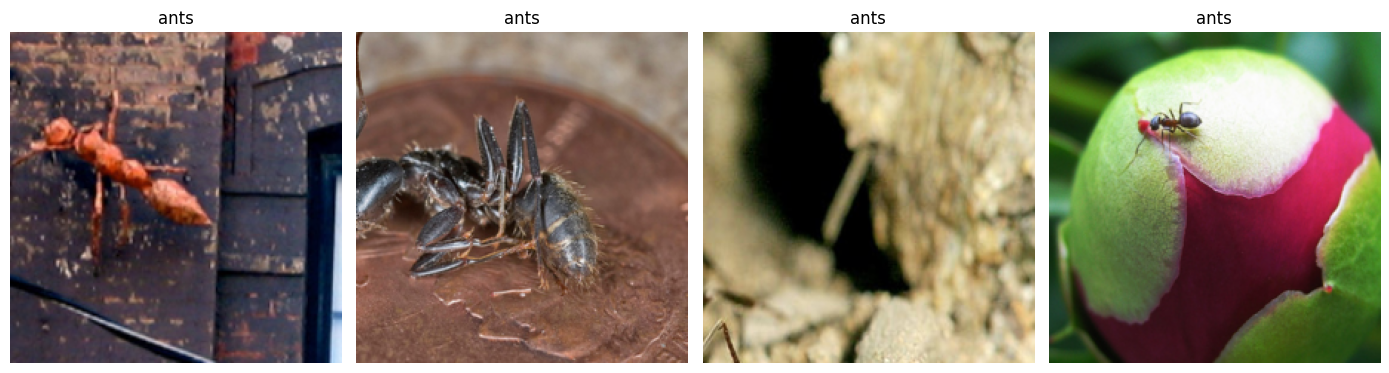

In [57]:
images, labels = next(iter(dataloaders["train"]))

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i, ax in enumerate(axes):

    img = images[i].permute(1, 2, 0).numpy()

    img = std * img + mean
    img = np.clip(img, 0, 1)

    ax.imshow(img)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

### Training function

In [63]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=10):

    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(num_epochs):

        print(f"Epoch {epoch+1}/{num_epochs}")
        print("-" * 30)

        for phase in ["train", "val"]:

            if phase == "train":
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:

                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):

                    outputs = model(inputs)

                    loss = criterion(outputs, labels)

                    preds = torch.argmax(outputs, dim=1)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)

                running_corrects += (
                    preds == labels
                ).sum().item()

            if phase == "train":
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]

            epoch_acc = (
                running_corrects
                / dataset_sizes[phase]
            )

            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc * 100)

            print(
                f"{phase} Loss: {epoch_loss:.4f} "
                f"Acc: {epoch_acc * 100:.2f}%"
            )

            # Save best validation model
            if phase == "val" and epoch_acc > best_acc:

                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(
                    model.state_dict()
                )

        print()

    time_elapsed = time.time() - since

    print(f"Training time: {time_elapsed:.2f} seconds")
    print(f"Best validation accuracy: {best_acc * 100:.2f}%")

    # Restore best validation model
    model.load_state_dict(best_model_wts)

    return model, history, time_elapsed

## Q3(a) - Fine-tuning ResNet-18

### Configure fine-tuning

In [64]:
# Load ResNet-18 pretrained on ImageNet-1K
model_ft = models.resnet18(
    weights=ResNet18_Weights.IMAGENET1K_V1
)

# Number of input features to final FC layer
num_ftrs = model_ft.fc.in_features

# Replace output layer with 2 classes
model_ft.fc = nn.Linear(num_ftrs, 2)

model_ft = model_ft.to(device)

# Cross-entropy loss
criterion = nn.CrossEntropyLoss()

# Optimize all network parameters
optimizer_ft = optim.SGD(
    model_ft.parameters(),
    lr=0.001,
    momentum=0.9
)

# Reduce learning rate every 7 epochs
scheduler_ft = lr_scheduler.StepLR(
    optimizer_ft,
    step_size=7,
    gamma=0.1
)

print("Fine-tuning model ready!")
print("Output layer:", model_ft.fc)

Fine-tuning model ready!
Output layer: Linear(in_features=512, out_features=2, bias=True)


### Check trainable parameters

In [65]:
total_params_ft = sum(
    p.numel() for p in model_ft.parameters()
)

trainable_params_ft = sum(
    p.numel()
    for p in model_ft.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params_ft)
print("Trainable parameters:", trainable_params_ft)

Total parameters: 11177538
Trainable parameters: 11177538


### Train the fine-tuning model

In [66]:
model_ft, history_ft, time_ft = train_model(
    model_ft,
    criterion,
    optimizer_ft,
    scheduler_ft,
    num_epochs=10
)

Epoch 1/10
------------------------------
train Loss: 0.6254 Acc: 65.16%
val Loss: 0.2430 Acc: 89.54%

Epoch 2/10
------------------------------
train Loss: 0.5773 Acc: 75.82%
val Loss: 0.2341 Acc: 90.85%

Epoch 3/10
------------------------------
train Loss: 0.6619 Acc: 78.28%
val Loss: 1.7252 Acc: 69.93%

Epoch 4/10
------------------------------
train Loss: 0.7821 Acc: 75.82%
val Loss: 1.2385 Acc: 80.39%

Epoch 5/10
------------------------------
train Loss: 0.5232 Acc: 79.92%
val Loss: 0.3888 Acc: 86.93%

Epoch 6/10
------------------------------
train Loss: 0.4783 Acc: 81.56%
val Loss: 0.2461 Acc: 92.16%

Epoch 7/10
------------------------------
train Loss: 0.4631 Acc: 81.97%
val Loss: 0.2533 Acc: 92.16%

Epoch 8/10
------------------------------
train Loss: 0.3841 Acc: 84.84%
val Loss: 0.2542 Acc: 89.54%

Epoch 9/10
------------------------------
train Loss: 0.3014 Acc: 84.84%
val Loss: 0.2111 Acc: 92.16%

Epoch 10/10
------------------------------
train Loss: 0.3381 Acc: 86.48%

### Save the model

In [67]:
torch.save(
    model_ft.state_dict(),
    "Q3_ResNet18_FineTuning.pth"
)

print("Fine-tuned model saved.")

Fine-tuned model saved.


## Q3(b) - ResNet-18 as a fixed feature extractor

## Freeze the pretrained network

In [68]:
model_conv = models.resnet18(
    weights=ResNet18_Weights.IMAGENET1K_V1
)

# Freeze pretrained parameters
for param in model_conv.parameters():
    param.requires_grad = False

# Replace classification layer
num_ftrs = model_conv.fc.in_features

model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

# Optimize only the new FC layer
optimizer_conv = optim.SGD(
    model_conv.fc.parameters(),
    lr=0.001,
    momentum=0.9
)

scheduler_conv = lr_scheduler.StepLR(
    optimizer_conv,
    step_size=7,
    gamma=0.1
)

print("Feature extraction model ready!")
print("Output layer:", model_conv.fc)

Feature extraction model ready!
Output layer: Linear(in_features=512, out_features=2, bias=True)


### Check trainable parameters

In [69]:
total_params_conv = sum(
    p.numel() for p in model_conv.parameters()
)

trainable_params_conv = sum(
    p.numel()
    for p in model_conv.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params_conv)
print("Trainable parameters:", trainable_params_conv)

Total parameters: 11177538
Trainable parameters: 1026


### Train the feature-extraction model

In [70]:
model_conv, history_conv, time_conv = train_model(
    model_conv,
    criterion,
    optimizer_conv,
    scheduler_conv,
    num_epochs=10
)

Epoch 1/10
------------------------------
train Loss: 0.6065 Acc: 63.52%
val Loss: 0.5491 Acc: 73.86%

Epoch 2/10
------------------------------
train Loss: 0.6118 Acc: 71.31%
val Loss: 0.2058 Acc: 90.85%

Epoch 3/10
------------------------------
train Loss: 0.3839 Acc: 80.74%
val Loss: 0.1995 Acc: 93.46%

Epoch 4/10
------------------------------
train Loss: 0.3896 Acc: 81.97%
val Loss: 0.2149 Acc: 92.81%

Epoch 5/10
------------------------------
train Loss: 0.4753 Acc: 80.74%
val Loss: 0.2163 Acc: 91.50%

Epoch 6/10
------------------------------
train Loss: 0.6166 Acc: 77.46%
val Loss: 0.3079 Acc: 88.89%

Epoch 7/10
------------------------------
train Loss: 0.5544 Acc: 75.82%
val Loss: 0.2223 Acc: 93.46%

Epoch 8/10
------------------------------
train Loss: 0.4300 Acc: 81.56%
val Loss: 0.2710 Acc: 90.85%

Epoch 9/10
------------------------------
train Loss: 0.2196 Acc: 91.80%
val Loss: 0.1835 Acc: 94.77%

Epoch 10/10
------------------------------
train Loss: 0.4077 Acc: 82.38%

### Save the model

In [71]:
torch.save(
    model_conv.state_dict(),
    "Q3_ResNet18_FeatureExtraction.pth"
)

print("Feature extraction model saved.")

Feature extraction model saved.


## Compare fine-tuning and feature extraction

### Plot accuracy and loss curves

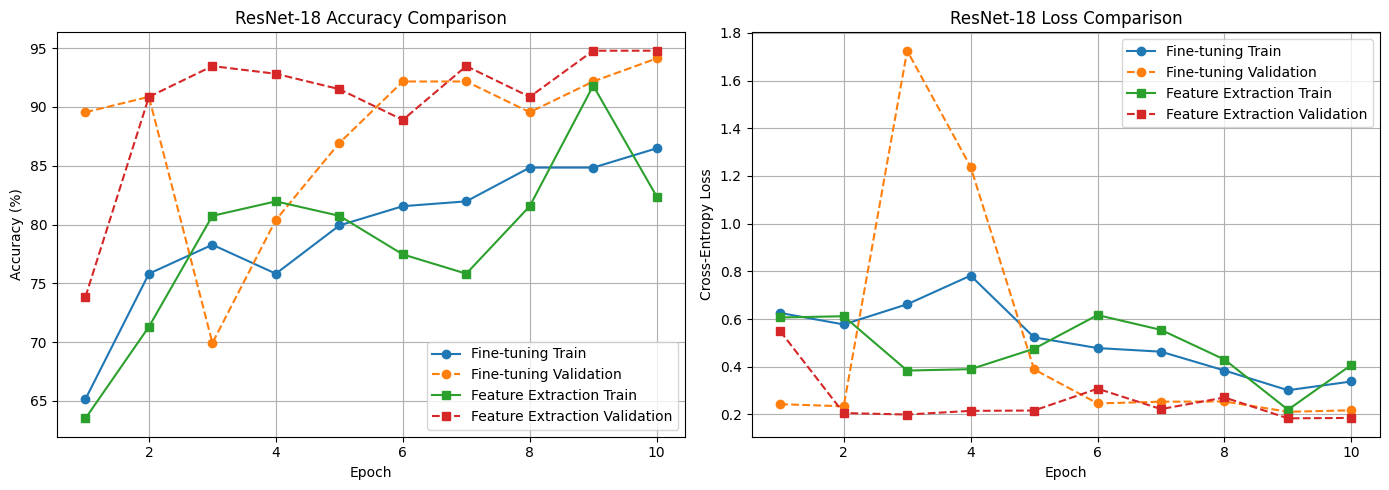

In [72]:
epochs = range(1, 11)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy comparison
axes[0].plot(
    epochs, history_ft["train_acc"],
    "o-", label="Fine-tuning Train"
)

axes[0].plot(
    epochs, history_ft["val_acc"],
    "o--", label="Fine-tuning Validation"
)

axes[0].plot(
    epochs, history_conv["train_acc"],
    "s-", label="Feature Extraction Train"
)

axes[0].plot(
    epochs, history_conv["val_acc"],
    "s--", label="Feature Extraction Validation"
)

axes[0].set_title("ResNet-18 Accuracy Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(True)

# Loss comparison
axes[1].plot(
    epochs, history_ft["train_loss"],
    "o-", label="Fine-tuning Train"
)

axes[1].plot(
    epochs, history_ft["val_loss"],
    "o--", label="Fine-tuning Validation"
)

axes[1].plot(
    epochs, history_conv["train_loss"],
    "s-", label="Feature Extraction Train"
)

axes[1].plot(
    epochs, history_conv["val_loss"],
    "s--", label="Feature Extraction Validation"
)

axes[1].set_title("ResNet-18 Loss Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("Q3_Training_Comparison.png", dpi=200)
plt.show()

### Generate confusion matrices

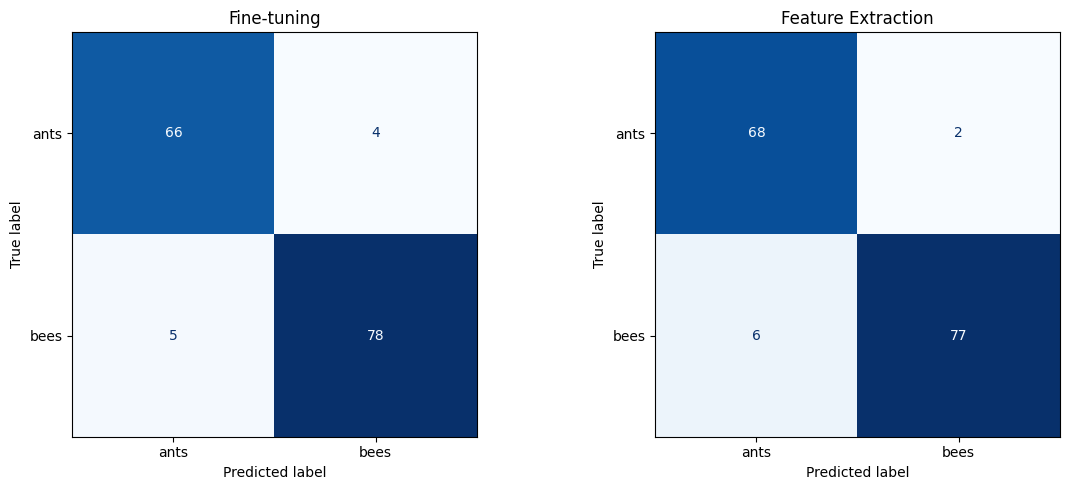

In [73]:
def get_predictions(model, loader):

    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    return y_true, y_pred


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, model, title in zip(
    axes,
    [model_ft, model_conv],
    ["Fine-tuning", "Feature Extraction"]
):

    y_true, y_pred = get_predictions(
        model, dataloaders["val"]
    )

    cm = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)

plt.tight_layout()
plt.savefig("Q3_Confusion_Matrices.png", dpi=200)
plt.show()

### Final results summary

In [74]:
print("=" * 65)
print("Q3: RESNET-18 TRANSFER LEARNING COMPARISON")
print("=" * 65)

print(
    f"{'Method':<22} "
    f"{'Best Val Acc':>14} "
    f"{'Time (s)':>12} "
    f"{'Trainable Params':>18}"
)

print("-" * 70)

print(
    f"{'Fine-tuning':<22} "
    f"{max(history_ft['val_acc']):>13.2f}% "
    f"{time_ft:>12.2f} "
    f"{trainable_params_ft:>18,}"
)

print(
    f"{'Feature Extraction':<22} "
    f"{max(history_conv['val_acc']):>13.2f}% "
    f"{time_conv:>12.2f} "
    f"{trainable_params_conv:>18,}"
)

Q3: RESNET-18 TRANSFER LEARNING COMPARISON
Method                   Best Val Acc     Time (s)   Trainable Params
----------------------------------------------------------------------
Fine-tuning                    94.12%        29.83         11,177,538
Feature Extraction             94.77%        35.01              1,026


## Question 3 - Results and Discussion

Transfer learning was performed using an ImageNet-pretrained ResNet-18 to classify ants and bees. Two approaches were compared: **fine-tuning** the entire network and **feature extraction**, where only the final classification layer was trained.

| Metric | Fine-tuning | Feature Extraction |
|---|---:|---:|
| Best validation accuracy | 94.12% | 94.77% |
| Trainable parameters | 11,177,538 | 1,026 |
| Training time | 29.83 s | 35.01 s |

Both approaches achieved validation accuracies above 94%, demonstrating the effectiveness of pretrained ImageNet features.

Feature extraction achieved slightly higher accuracy despite training significantly fewer parameters. However, the difference corresponds to only **one additional correctly classified image**, so it does not establish a consistent performance advantage.

The training curves showed some fluctuations, possibly due to the small dataset and training conditions. Although feature extraction took slightly longer in this run, execution times can vary due to runtime and data-loading overhead.

**Conclusion:** Both approaches performed well, while feature extraction achieved comparable accuracy with significantly fewer trainable parameters. Fine-tuning remains useful when greater adaptation to the target dataset is required.